In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_diabetes

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

In [2]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038,0.051,0.062,0.022,-0.044,-0.035,-0.043,-0.003,0.020,-0.018,151.0
1,-0.002,-0.045,-0.051,-0.026,-0.008,-0.019,0.074,-0.039,-0.068,-0.092,75.0
2,0.085,0.051,0.044,-0.006,-0.046,-0.034,-0.032,-0.003,0.003,-0.026,141.0
3,-0.089,-0.045,-0.012,-0.037,0.012,0.025,-0.036,0.034,0.023,-0.009,206.0
4,0.005,-0.045,-0.036,0.022,0.004,0.016,0.008,-0.003,-0.032,-0.047,135.0


In [3]:
print("Dependent variable: target")
print("Independent variables:", list(df.columns[:-1]))

Dependent variable: target
Independent variables: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [4]:
correlation = df.corr()

print(correlation["target"].sort_values(ascending=False))

target    1.000
bmi       0.586
s5        0.566
bp        0.441
s4        0.430
s6        0.382
s1        0.212
age       0.188
s2        0.174
sex       0.043
s3       -0.395
Name: target, dtype: float64


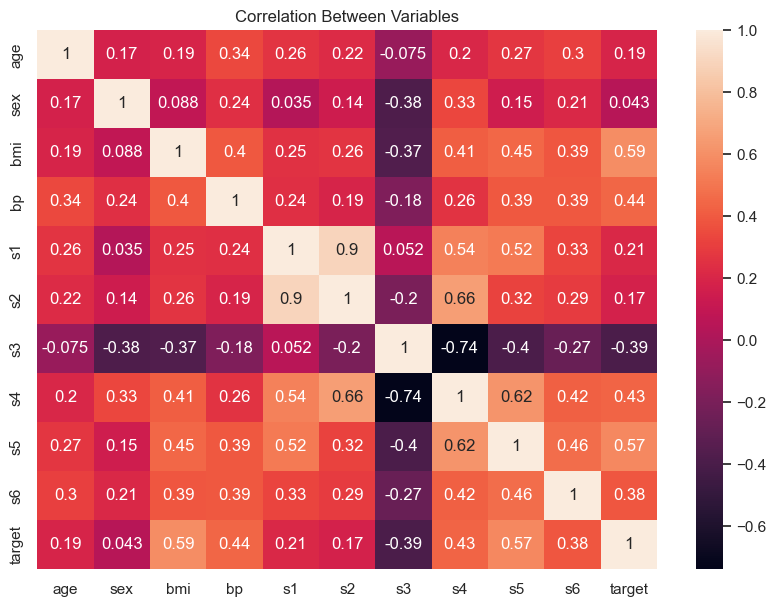

In [9]:
plt.figure(figsize=(10, 7))

sns.heatmap(correlation, annot=True)

plt.title("Correlation Between Variables")
plt.show()

In [10]:
r, p = stats.pearsonr(df["bmi"], df["target"])

print("Pearson Correlation:", r)
print("P-value:", p)

Pearson Correlation: 0.5864501344746886
P-value: 3.4660064451673575e-42


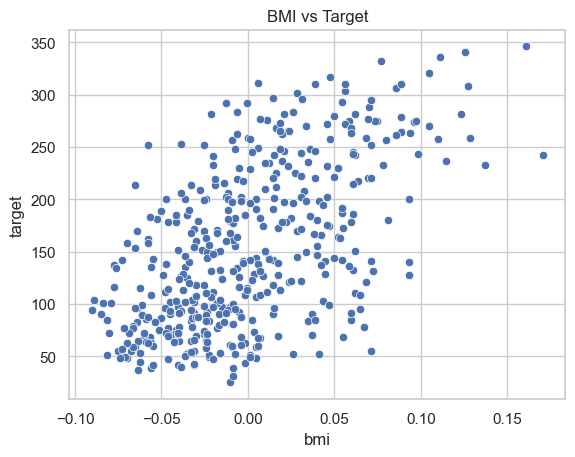

In [11]:
sns.scatterplot(data=df, x="bmi", y="target")
plt.title("BMI vs Target")
plt.show()

In [12]:
correlations = {}

for column in df.columns[:-1]:
    r, p = stats.pearsonr(df[column], df["target"])
    correlations[column] = [r, p]

results = pd.DataFrame(
    correlations,
    index=["Correlation (r)", "P-value"]
).T

results

,Correlation (r),P-value
age,0.188,7.056e-05
sex,0.043,3.664e-01
bmi,0.586,3.466e-42
bp,0.441,1.649e-22
s1,0.212,6.921e-06
s2,0.174,2.360e-04
s3,-0.395,6.163e-18
s4,0.430,2.304e-21
s5,0.566,8.826e-39
s6,0.382,7.580e-17


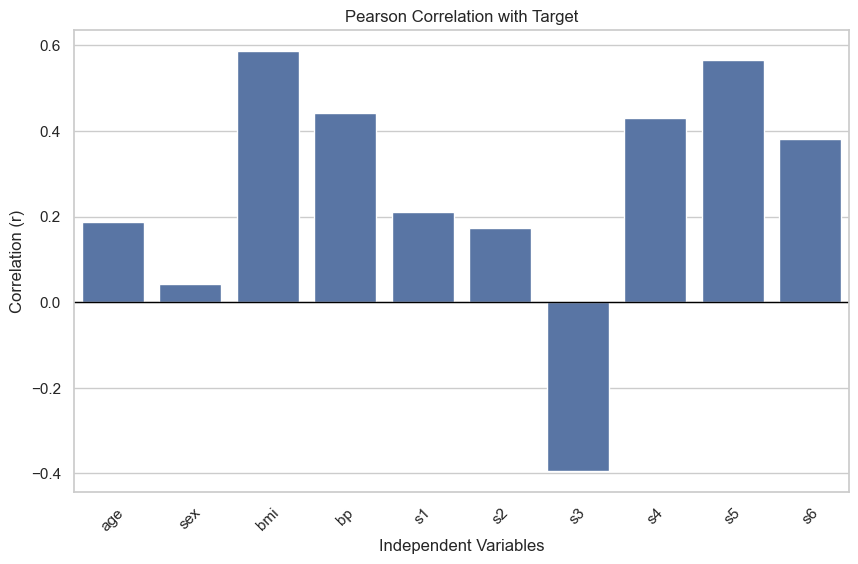

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=results.index,
    y=results["Correlation (r)"]
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Pearson Correlation with Target")
plt.xlabel("Independent Variables")
plt.ylabel("Correlation (r)")
plt.xticks(rotation=45)

plt.show()